# Proyecto final · 04 · Entrenamiento de BART-base

Segunda etapa del pipeline, la tarea de **generación de lenguaje**: se afinan todos los pesos de BART-base con los 56.254 pares de `train.jsonl` (notebook 03) para que, dada una oración con errores, genere su versión corregida. No hay prompting ni capas añadidas: el modelo aprende la tarea solo de los ejemplos.

```mermaid
flowchart LR
    A[train.jsonl<br/>56.254 pares] --> B[lote de 32<br/>piezas BPE]
    B --> C[BART-base<br/>codificador + decodificador]
    C --> D[pérdida<br/>entropía cruzada]
    D -->|AdamW ajusta<br/>los 139 M pesos| C
    C -->|fin de época| E[genera dev_seleccion<br/>beam search]
    E --> F[ERRANT · F0.5]
    F -->|mejor F0.5| G[modelos/bart-base-gec/mejor]
```

El notebook arma el pipeline de entrenamiento pieza por pieza: modelo, datos, lote, argumentos, métrica y `Seq2SeqTrainer`. Cada pieza es una función de `src/entrenar.py` (la medición está en `src/evaluacion.py`, con tests), así que `make entrenar` ejecuta exactamente lo mismo desde la terminal.

El entrenamiento dura cerca de una hora. La celda que lo lanza (sección 4.5) solo entrena si `modelos/bart-base-gec/mejor/` no existe; si ya existe, el notebook sigue con lo que dejó el entrenamiento. Para volver a entrenar desde aquí basta con borrar esa carpeta.

In [1]:
import json
import os
import sys
import warnings
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_DATASETS_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")
RAIZ = Path("..").resolve()
sys.path.insert(0, str(RAIZ / "src"))
import entrenar
import evaluacion
from graficas import AZUL, NARANJA, AQUA, TINTA_SECUNDARIA, aplicar_estilo
import inspect
from IPython.display import Markdown
from transformers import AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()

DATOS, SALIDA, FIG = RAIZ / "datos" / "procesados" / "entrenamiento", RAIZ / "modelos" / "bart-base-gec", RAIZ / "figuras"
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)
aplicar_estilo()
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.cuda.get_device_name(0) if DISPOSITIVO == "cuda" else "sin GPU")

NVIDIA GeForce RTX 4060 Ti


## 1 · Configuración

Cada valor sale de una decisión anterior o de una prueba en la torre:

In [2]:
config = entrenar.Config()
por_que = {
    "modelo": "BART-base: seq2seq preentrenado para reconstruir texto dañado; cabe holgado en 16 GB",
    "epocas": "máximo; la parada temprana corta antes si F0.5 deja de mejorar",
    "lote": "prueba de humo: 234 pares/s con 4,4 GB; 64 rozó el límite de memoria",
    "tasa": "tasa habitual para afinar BART-base; más alta olvida el preentrenamiento",
    "calentamiento": "el 5 % de los pasos sube la tasa desde 0, para no romper los pesos al inicio",
    "decaimiento": "weight decay de AdamW: penaliza pesos grandes",
    "suavizado": "label smoothing: no exige probabilidad 1 a la pieza correcta; generaliza mejor",
    "largo": "128 piezas, entrega 1; se recortan 15 de 56.254 pares (notebook 03)",
    "haces": "beam search con 4 haces al generar",
    "paciencia": "épocas sin mejorar F0.5 en dev_seleccion antes de parar",
    "semilla": "reproducibilidad",
    "muestra": "solo para pruebas rápidas; None = todos los datos",
}
pd.DataFrame([{"parámetro": k, "valor": v, "por qué": por_que[k]} for k, v in asdict(config).items()]).set_index("parámetro")

,valor,por qué
parámetro,,
modelo,facebook/bart-base,BART-base: seq2seq preentrenado para reconstruir texto dañado; cabe holgado en 16 GB
epocas,10,máximo; la parada temprana corta antes si F0.5 deja de mejorar
lote,32,"prueba de humo: 234 pares/s con 4,4 GB; 64 rozó el límite de memoria"
tasa,0.00003,tasa habitual para afinar BART-base; más alta olvida el preentrenamiento
calentamiento,0.05,"el 5 % de los pasos sube la tasa desde 0, para no romper los pesos al inicio"
decaimiento,0.01,weight decay de AdamW: penaliza pesos grandes
suavizado,0.1,label smoothing: no exige probabilidad 1 a la pieza correcta; generaliza mejor
largo,128,"128 piezas, entrega 1; se recortan 15 de 56.254 pares (notebook 03)"
haces,4,beam search con 4 haces al generar


## 2 · El modelo de partida

`facebook/bart-base` ya sabe inglés: se preentrenó reconstruyendo texto al que se le borraron, mezclaron o taparon partes. Corregir errores es una tarea muy parecida, por eso basta con afinarlo.

In [3]:
# Paso 1 del pipeline
tokenizador, modelo = entrenar.cargar_modelo(config)
modelo.to(DISPOSITIVO)
c = modelo.config
pd.Series({
    "parámetros": f"{sum(p.numel() for p in modelo.parameters()) / 1e6:.0f} M",
    "capas del codificador": c.encoder_layers,
    "capas del decodificador": c.decoder_layers,
    "dimensión de los vectores": c.d_model,
    "cabezas de atención": c.encoder_attention_heads,
    "vocabulario BPE": f"{c.vocab_size:,} piezas",
}, name="BART-base").to_frame()

,BART-base
parámetros,139 M
capas del codificador,6
capas del decodificador,6
dimensión de los vectores,768
cabezas de atención,12
vocabulario BPE,"50,265 piezas"


### Un ajuste necesario: `no_repeat_ngram_size`

La configuración de generación de BART-base trae `no_repeat_ngram_size = 3`: le prohíbe repetir cualquier secuencia de tres piezas. Sirve para resumir noticias, pero un corrector **tiene que copiar** la oración, y las oraciones reales repiten secuencias. Con BART-base sin afinar (que solo sabe copiar) se ve el efecto:

In [4]:
def generar(modelo, textos, **opciones):
    x = tokenizador(textos, return_tensors="pt", padding=True).to(DISPOSITIVO)
    with torch.no_grad():
        salida = modelo.generate(**x, num_beams=4, max_length=128, **opciones)
    return [t.strip() for t in tokenizador.batch_decode(salida, skip_special_tokens=True)]

frase = ["I think that it is a good idea and I think that it is cheap."]
print("no_repeat_ngram_size = 3:", generar(modelo, frase, no_repeat_ngram_size=3)[0])
print("no_repeat_ngram_size = 0:", generar(modelo, frase, no_repeat_ngram_size=0)[0])

no_repeat_ngram_size = 3: I think that it is a good idea and I think that the it is cheap.
no_repeat_ngram_size = 0: I think that it is a good idea and I think that it is cheap.


Con 3, el modelo se ve obligado a alterar la segunda mitad: inventaría errores donde no los hay. `entrenar.cargar_modelo` lo deja en 0 y guarda con el modelo `max_length = 128` y `num_beams = 4`, para que la app y el notebook 05 generen igual que en la selección del checkpoint:

In [5]:
Markdown(f"```python\n{inspect.getsource(entrenar.cargar_modelo)}```")

```python
def cargar_modelo(config: Config):
    """Tokenizador y modelo preentrenados, con la generación ajustada para corregir."""
    tokenizador = AutoTokenizer.from_pretrained(config.modelo)
    modelo = AutoModelForSeq2SeqLM.from_pretrained(config.modelo)
    # bart-base prohíbe repetir trigramas al generar; en corrección hay que poder copiar "in the ... in the"
    modelo.generation_config.no_repeat_ngram_size = 0
    # Quedan guardados con el modelo: la app y el notebook 05 generan igual que la selección
    modelo.generation_config.max_length = config.largo
    modelo.generation_config.num_beams = config.haces
    return tokenizador, modelo
```

## 3 · Un lote por dentro

El `DataCollatorForSeq2Seq` junta pares de largos distintos en un lote rectangular:

- `input_ids` se rellena con la pieza `<pad>` (id 1) y `attention_mask` marca con 0 el relleno, para que el codificador lo ignore;
- `labels` se rellena con **-100**, el valor que la pérdida ignora;
- `decoder_input_ids` es `labels` corrido una posición a la derecha: para predecir la pieza *i*, el decodificador ve las piezas correctas hasta *i-1* (*teacher forcing*).

In [6]:
pares = [
    {"original": "She don't know.", "corregida": "She doesn't know."},
    {"original": "I am in charge for organise it.", "corregida": "I am in charge of organising it."},
]
tokenizar = entrenar.tokenizar_pares(tokenizador, config.largo)
lote = DataCollatorForSeq2Seq(tokenizador, model=modelo)(
    [{k: v[i] for k, v in tokenizar({"original": [p["original"] for p in pares],
                                       "corregida": [p["corregida"] for p in pares]}).items()} for i in range(len(pares))])
for clave in ["input_ids", "attention_mask", "labels", "decoder_input_ids"]:
    print(f"{clave:18}", lote[clave][0].tolist())
print()
piezas = lambda ids: [tokenizador.convert_ids_to_tokens(int(i)) if i >= 0 else "·" for i in ids]
pd.DataFrame({"decoder_input_ids (ve)": piezas(lote["decoder_input_ids"][0]),
              "labels (debe predecir)": piezas(lote["labels"][0])}).T

input_ids          [0, 2515, 218, 75, 216, 4, 2, 1, 1, 1]
attention_mask     [1, 1, 1, 1, 1, 1, 1, 0, 0, 0]
labels             [0, 2515, 630, 75, 216, 4, 2, -100, -100, -100]
decoder_input_ids  [2, 0, 2515, 630, 75, 216, 4, 2, 1, 1]



,0,1,2,3,4,5,6,7,8,9
decoder_input_ids (ve),</s>,<s>,She,Ġdoesn,'t,Ġknow,.,</s>,<pad>,<pad>
labels (debe predecir),<s>,She,Ġdoesn,'t,Ġknow,.,</s>,·,·,·


En cada posición el decodificador produce una probabilidad para cada una de las 50.265 piezas. La **pérdida** es la entropía cruzada: cuánta probabilidad le dio a la pieza correcta (`labels`), promediada sobre las piezas que no son -100. AdamW ajusta los pesos para subir esa probabilidad, lote a lote.

## 4 · El pipeline de entrenamiento

### 4.1 · Datos

`entrenar.preparar_datos` lee `train.jsonl` y `dev_seleccion` y los tokeniza con la función de la sección 3. El Trainer necesita los dos tokenizados; para medir F0.5 se guarda además `dev_seleccion` tal cual (texto natural, tokens del M2 y referencia).

In [7]:
train_ds, dev_ds, dev = entrenar.preparar_datos(config, DATOS, tokenizador)
print("train:", train_ds)
print("dev:  ", dev_ds)
# El primer par de train que tiene correcciones
ejemplo = next(e for e in train_ds if e["input_ids"] != e["labels"])
print()
print("original :", tokenizador.decode(ejemplo["input_ids"]))
print("corregida:", tokenizador.decode(ejemplo["labels"]))

train: Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 56254
})
dev:   Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 5054
})

original : <s>I am writing in order to express my disappointment about your musical show "Over the Rainbow".</s>
corregida: <s>I am writing in order to express my disappointment with your musical show "Over the Rainbow".</s>


### 4.2 · Argumentos del entrenamiento

`entrenar.argumentos` traduce la configuración de la sección 1 a `Seq2SeqTrainingArguments`. Los que definen el comportamiento:

In [8]:
args = entrenar.argumentos(config, SALIDA, len(train_ds))
pasos_por_epoca = -(-len(train_ds) // config.lote)
pd.DataFrame([
    ("num_train_epochs", args.num_train_epochs, "épocas como máximo"),
    ("per_device_train_batch_size", args.per_device_train_batch_size, f"{pasos_por_epoca:,} pasos por época"),
    ("learning_rate", args.learning_rate, "AdamW, con decaimiento lineal hasta 0"),
    ("warmup_steps", args.warmup_steps, "5 % de los pasos"),
    ("bf16", args.bf16, "precisión mixta en la GPU"),
    ("label_smoothing_factor", args.label_smoothing_factor, "suavizado de la pérdida"),
    ("eval_strategy", str(args.eval_strategy.value), "medir F0.5 al final de cada época"),
    ("eval_on_start", args.eval_on_start, "medir también antes de entrenar (época 0)"),
    ("predict_with_generate", args.predict_with_generate, "evaluar generando, no solo con la pérdida"),
    ("generation_num_beams", args.generation_num_beams, "beam search"),
    ("metric_for_best_model", args.metric_for_best_model, "el checkpoint se elige por F0.5"),
    ("load_best_model_at_end", args.load_best_model_at_end, "al terminar queda cargado el mejor"),
    ("save_total_limit", args.save_total_limit, "en disco: el mejor y el último"),
], columns=["argumento", "valor", "para qué"]).set_index("argumento")

,valor,para qué
argumento,,
num_train_epochs,10,épocas como máximo
per_device_train_batch_size,32,"1,758 pasos por época"
learning_rate,0.00003,"AdamW, con decaimiento lineal hasta 0"
warmup_steps,879,5 % de los pasos
bf16,True,precisión mixta en la GPU
label_smoothing_factor,0.1,suavizado de la pérdida
eval_strategy,epoch,medir F0.5 al final de cada época
eval_on_start,True,medir también antes de entrenar (época 0)
predict_with_generate,True,"evaluar generando, no solo con la pérdida"


### 4.3 · La métrica de cada época

Después de cada época el Trainer genera todo `dev_seleccion` y llama a esta función con los ids generados. Los convierte en texto, guarda las predicciones y devuelve el F0.5 de ERRANT, con el mismo camino que fijó el techo de 0,855 (tokenizar con spaCy, `errant_parallel`, `errant_compare`):

In [9]:
Markdown(f"```python\n{inspect.getsource(entrenar.metrica_f05)}```")

```python
def metrica_f05(tokenizador, dev: evaluacion.Conjunto, carpeta_predicciones: Path):
    """compute_metrics: decodifica lo generado, guarda las predicciones y devuelve F0.5 de ERRANT."""
    carpeta_predicciones.mkdir(parents=True, exist_ok=True)
    llamadas = 0

    def calcular(prediccion):
        nonlocal llamadas
        ids = np.where(prediccion.predictions != -100, prediccion.predictions, tokenizador.pad_token_id)
        textos = [t.strip() for t in tokenizador.batch_decode(ids, skip_special_tokens=True)]
        with (carpeta_predicciones / f"evaluacion_{llamadas:02d}.jsonl").open("w", encoding="utf-8") as f:
            for fila, texto in zip(dev.entrada, textos):
                f.write(json.dumps({"id": fila["id"], "prediccion": texto}, ensure_ascii=False) + "\n")
        llamadas += 1
        r = evaluacion.f05(dev, evaluacion.tokenizar(textos))
        return {"f05": r["f05"], "precision": r["precision"], "recall": r["recall"]}

    return calcular
```

### 4.4 · El Trainer

`entrenar.crear_trainer` junta todo: modelo, argumentos, datos, collator, tokenizador, métrica y dos *callbacks*. `Registro` escribe cada log en `registro.jsonl` y `EarlyStoppingCallback` para el entrenamiento si F0.5 no mejora en 3 épocas seguidas.

In [10]:
trainer = entrenar.crear_trainer(config, SALIDA, tokenizador, modelo, train_ds, dev_ds, dev)
print(f"{len(train_ds):,} pares · {pasos_por_epoca:,} pasos por época · hasta {pasos_por_epoca * config.epocas:,} pasos")
print("callbacks:", [type(cb).__name__ for cb in trainer.callback_handler.callbacks])

56,254 pares · 1,758 pasos por época · hasta 17,580 pasos
callbacks: ['DefaultFlowCallback', 'Registro', 'EarlyStoppingCallback', 'PrinterCallback']


### 4.5 · Entrenar

`entrenar.ejecutar` llama a `trainer.train()` y guarda el mejor checkpoint en `mejor/`. En cada paso: un lote de 32 pares → el modelo predice cada pieza de la corrección → pérdida → AdamW ajusta los 139 M pesos. Desde la terminal de la torre, lo mismo es `make entrenar` (y `make progreso` para seguirlo).

In [11]:
if (SALIDA / "mejor").exists():
    print("Ya hay un modelo entrenado; se usan sus resultados:", json.loads((SALIDA / "mejor" / "elegido.json").read_text()))
else:
    entrenar.ejecutar(trainer, config, SALIDA)
print(sorted(p.name for p in SALIDA.iterdir()))

Ya hay un modelo entrenado; se usan sus resultados: {'checkpoint': '/work/modelos/bart-base-gec/checkpoint-3516', 'f05_dev_seleccion': 0.5029}
['checkpoint-3516', 'checkpoint-8790', 'config.json', 'mejor', 'predicciones', 'registro.jsonl']


## 5 · Curvas de entrenamiento

`registro.jsonl` tiene la pérdida de train cada 50 pasos y, por época, la pérdida y el F0.5 en `dev_seleccion`.

In [12]:
registro = [json.loads(l) for l in (SALIDA / "registro.jsonl").read_text().splitlines()]
perdida = pd.DataFrame([r for r in registro if "loss" in r])[["paso", "epoca", "loss"]]
epocas = pd.DataFrame([r for r in registro if "eval_f05" in r])[
    ["epoca", "paso", "eval_loss", "eval_precision", "eval_recall", "eval_f05", "eval_runtime"]]
epocas.columns = ["época", "paso", "pérdida dev", "precisión", "recall", "F0.5", "segundos de evaluación"]
epocas["época"] = epocas["época"].round().astype(int)
resumen_train = next(r for r in registro if "train_runtime" in r)
print(f"entrenamiento: {resumen_train['train_runtime'] / 60:.0f} min · {resumen_train['epoch']:.0f} épocas · "
      f"{resumen_train['train_samples_per_second']:.0f} pares/s (incluye las evaluaciones)")
epocas.set_index("época")

entrenamiento: 30 min · 5 épocas · 159 pares/s (incluye las evaluaciones)


,paso,pérdida dev,precisión,recall,F0.5,segundos de evaluación
época,,,,,,
0,0,4.048200,0.1321,0.0016,0.0074,113.3644
1,1758,1.772105,0.5830,0.2405,0.4538,111.5258
2,3516,1.733702,0.5973,0.3082,0.5029,112.4662
3,5274,1.723149,0.5732,0.3283,0.4988,112.6372
4,7032,1.716765,0.5472,0.3587,0.4951,112.9416
5,8790,1.725716,0.5351,0.3556,0.4860,113.0650


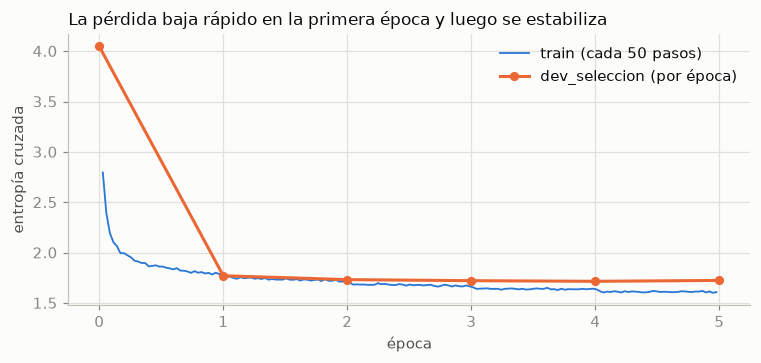

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(perdida.paso / pasos_por_epoca, perdida.loss, color=AZUL, linewidth=1.2, label="train (cada 50 pasos)")
ax.plot(epocas.paso / pasos_por_epoca, epocas["pérdida dev"], color=NARANJA, linewidth=2, marker="o", markersize=5,
        label="dev_seleccion (por época)")
ax.set_xlabel("época")
ax.set_ylabel("entropía cruzada")
ax.set_title("La pérdida baja rápido en la primera época y luego se estabiliza")
ax.legend(frameon=False)
fig.savefig(FIG / "14_perdida.png")
plt.show()

La pérdida incluye el *label smoothing* (0,1), por eso no baja a 0 aunque el modelo acierte casi todas las piezas: la mayoría son copias fáciles. La pérdida no dice si las **correcciones** son buenas; eso lo dice F0.5.

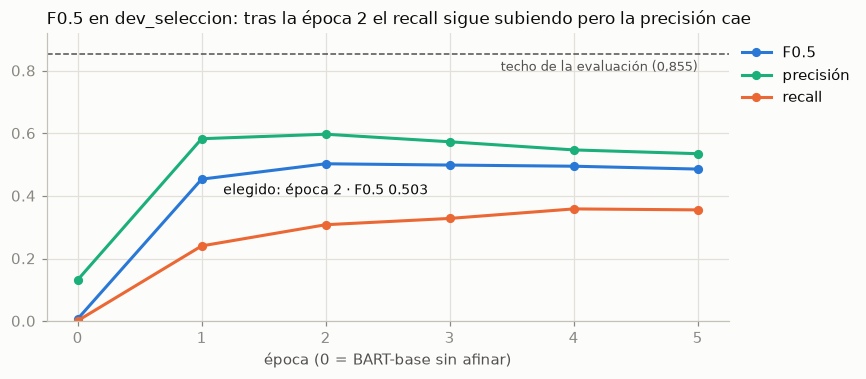

{'checkpoint': '/work/modelos/bart-base-gec/checkpoint-3516',
 'f05_dev_seleccion': 0.5029}

In [14]:
mejor = epocas.loc[epocas["F0.5"].idxmax()]
fig, ax = plt.subplots(figsize=(8, 3.4))
for col, color in [("F0.5", AZUL), ("precisión", AQUA), ("recall", NARANJA)]:
    ax.plot(epocas["época"], epocas[col], color=color, linewidth=2, marker="o", markersize=5, label=col)
ax.axhline(0.855, color=TINTA_SECUNDARIA, linewidth=1, linestyle="--")
ax.text(epocas["época"].max(), 0.835, "techo de la evaluación (0,855)", ha="right", va="top", color=TINTA_SECUNDARIA, fontsize=8.5)
ax.annotate(f"elegido: época {int(mejor['época'])} · F0.5 {mejor['F0.5']:.3f}", (mejor["época"], mejor["F0.5"]),
            xytext=(0, -20), textcoords="offset points", ha="center", fontsize=9)
ax.set_ylim(0, 0.92)
ax.set_xlabel("época (0 = BART-base sin afinar)")
ax.set_title("F0.5 en dev_seleccion: tras la época 2 el recall sigue subiendo pero la precisión cae")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
fig.savefig(FIG / "15_f05_por_epoca.png")
plt.show()
json.loads((SALIDA / "mejor" / "elegido.json").read_text())

## 6 · Qué aprendió

La oración del notebook 03 es del test, así que el modelo nunca la vio. Para cada pieza de la corrección, ¿qué probabilidad le dan BART-base y el modelo afinado, viendo las piezas anteriores correctas?

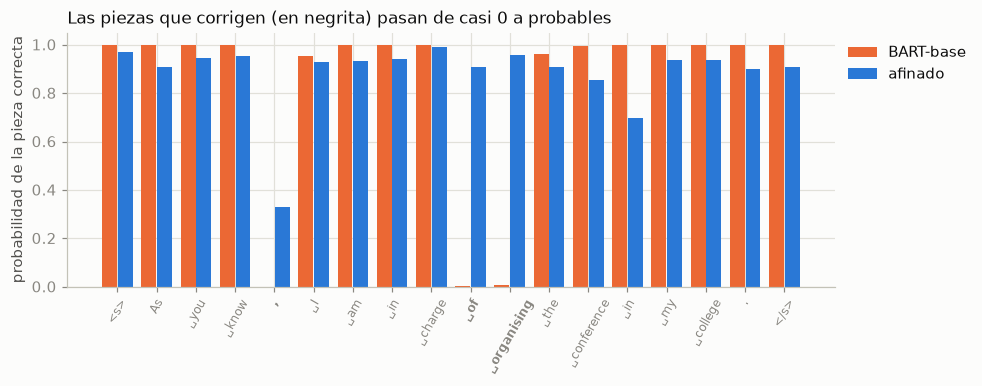

,pieza,BART-base,afinado
4,",",0.000,0.332
9,Ġof,0.002,0.909
10,Ġorganising,0.008,0.956


In [15]:
base = AutoModelForSeq2SeqLM.from_pretrained(config.modelo).to(DISPOSITIVO).eval()
afinado = AutoModelForSeq2SeqLM.from_pretrained(SALIDA / "mejor").to(DISPOSITIVO).eval()
original = "As you know I am in charge for organise the conference in my college."
corregida = "As you know, I am in charge of organising the conference in my college."

def prob_por_pieza(modelo):
    x = tokenizador(original, text_target=corregida, return_tensors="pt").to(DISPOSITIVO)
    with torch.no_grad():
        logits = modelo(**x).logits[0]
    return logits.softmax(-1)[torch.arange(len(x["labels"][0])), x["labels"][0]].cpu().numpy()

etiquetas = tokenizador(text_target=corregida)["input_ids"]
probs = pd.DataFrame({"pieza": tokenizador.convert_ids_to_tokens(etiquetas),
                      "BART-base": prob_por_pieza(base), "afinado": prob_por_pieza(afinado)})
cambian = probs.pieza.isin([",", "Ġof", "Ġorganising"])

fig, ax = plt.subplots(figsize=(9, 3))
x = np.arange(len(probs))
ax.bar(x - 0.2, probs["BART-base"], width=0.38, color=NARANJA, label="BART-base")
ax.bar(x + 0.2, probs["afinado"], width=0.38, color=AZUL, label="afinado")
ax.set_xticks(x, probs.pieza.str.replace("Ġ", "␣"), rotation=60, fontsize=8)
for t, c in zip(ax.get_xticklabels(), cambian):
    t.set_fontweight("bold" if c else "normal")
ax.set_ylabel("probabilidad de la pieza correcta")
ax.set_title("Las piezas que corrigen (en negrita) pasan de casi 0 a probables")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
fig.savefig(FIG / "16_probabilidad_por_pieza.png")
plt.show()
probs[cambian].round(3)

In [16]:
print("entrada:", original)
print("base   :", generar(base, [original], no_repeat_ngram_size=0)[0])
print("afinado:", generar(afinado, [original])[0])

entrada: As you know I am in charge for organise the conference in my college.
base   : As you know I am in charge for organise the conference in my college.
afinado: As you know I am in charge of organising the conference in my college.


El modelo afinado corrige la preposición y la forma verbal, que pasan a más de 0,9 de probabilidad. La coma después de *As you know* sube de 0 a 0,33, pero no basta para que el beam search la elija: el modelo es **conservador**, solo cambia cuando está bastante seguro. Es lo que premia F0.5.

## 7 · Una oración, época por época

`predicciones/evaluacion_NN.jsonl` guarda lo que generó el modelo para todo `dev_seleccion` en cada evaluación (00 = antes de entrenar). Se toman las primeras oraciones de dev con dos o más errores y largo moderado, sin elegirlas a mano:

In [17]:
dev = evaluacion.leer_conjunto(DATOS / "dev_seleccion")
n_ediciones = [sum(1 for l in b.split("\n")[1:] if "|||noop|||" not in l and l.endswith("|||0")) for b in dev.ref]
elegidas = [i for i, (e, n) in enumerate(zip(dev.entrada, n_ediciones)) if n >= 2 and 8 <= len(e["original"].split()) <= 18][:4]
evaluaciones = sorted((SALIDA / "predicciones").glob("evaluacion_*.jsonl"))
predicciones = [[json.loads(l)["prediccion"] for l in p.read_text().splitlines()] for p in evaluaciones]
for i in elegidas:
    print("original  :", dev.entrada[i]["original"])
    print("referencia:", dev.entrada[i]["corregida"])
    anterior = None
    for epoca, pred in enumerate(predicciones):
        if pred[i] != anterior:
            print(f"época {epoca:>2}  :", pred[i])
            anterior = pred[i]
    print(f"elegida {int(mejor['época'])} :", predicciones[int(mejor["época"])][i])
    print()

original  : Because I intend to take examination in Septenber.
referencia: This is because I intend to take an examination in September.
época  0  : Because I intend to take examination in Septenber.
época  1  : Because I intend to take examination in September.
elegida 2 : Because I intend to take examination in September.

original  : And nowadays, I have been practicing tennis as school activity.
referencia: And recently, I have been practising tennis as a school activity.
época  0  : And nowadays, I have been practicing tennis as school activity.
época  1  : And nowadays, I have been practicing tennis as a school activity.
época  3  : And nowadays, I have been playing tennis as a school activity.
elegida 2 : And nowadays, I have been practicing tennis as a school activity.

original  : Can you send me the letter back writing what happend to you recently.
referencia: Can you send me a letter back writing what happened to you recently?
época  0  : Can you send me the letter back writ

Solo se imprime una época cuando la salida cambia respecto a la anterior; la última línea es la del checkpoint elegido. Se ve el patrón de la sección 5: en la época 1 el modelo ya corrige ortografía y artículos; en las siguientes empieza a reescribir más (*practicing* → *playing*, *writing about*), lo que a veces acierta y a veces agrega cambios que la referencia no pide.

## Resumen

| | |
|---|---|
| Modelo | BART-base (139 M parámetros), todos los pesos afinados con 56.254 pares |
| Configuración | AdamW, tasa 3e-5, lote 32, bf16, label smoothing 0,1, largo 128, beam search de 4 |
| Selección | F0.5 de ERRANT en `dev_seleccion` por época; el test no se usa |
| Duración | 30 minutos en la RTX 4060 Ti; la parada temprana cortó en la época 5 |
| Resultado | época 2 elegida: **F0.5 = 0,503** en `dev_seleccion` (precisión 0,597, recall 0,308), contra 0,007 de BART-base sin afinar y un techo de 0,855 |
| Lectura | el modelo corrige poco pero bien: casi 6 de cada 10 cambios coinciden con la referencia y encuentra 3 de cada 10 errores |
| Siguiente | `05_evaluacion`: F0.5 en FCE test, en hispanohablantes de dev y de test, y por tipo de error |